# 02 — Exploratory Data Analysis
Quality audit and exploratory statistics of the harmonised site-day panel (185 capital-city
sites). Extreme values are **kept** unless physically impossible — extremes are the events the
system must detect.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:06 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
panel = pd.read_parquet(ROOT / "data/processed/panel.parquet")
obs = panel[panel.observed == 1]
print("site-days:", len(obs), "| sites:", obs.site_id.nunique(), "| dates:", obs.date.min().date(), "→", obs.date.max().date())
cols = ["temp_c_obs","rh_obs","wind_kph_obs","pressure_hpa_obs","precip_mm_obs","uv_index_obs","pm25_obs","pm10_obs","o3_obs","no2_obs","co_obs","so2_obs"]
obs[cols].describe(percentiles=[.01,.5,.99]).T.round(2)

site-days: 160496 | sites: 185 | dates: 2024-05-16 → 2026-10-12


,count,mean,std,min,1%,50%,99%,max
temp_c_obs,160496.0,21.44,9.29,-29.80,-3.9,23.60,39.20,49.20
rh_obs,160496.0,66.79,23.40,2.00,10.0,72.00,100.00,100.00
wind_kph_obs,160495.0,12.69,8.30,3.60,3.6,10.80,37.10,272.20
pressure_hpa_obs,160484.0,1014.12,6.94,851.00,997.0,1014.00,1032.00,1080.00
precip_mm_obs,160496.0,0.13,0.59,0.00,0.0,0.00,2.12,74.52
uv_index_obs,160496.0,3.09,3.50,0.00,0.0,1.50,12.80,16.30
pm25_obs,160496.0,23.06,34.91,0.10,0.8,13.35,153.75,1614.10
pm10_obs,160494.0,46.33,143.28,0.10,1.3,19.01,468.60,6037.29
o3_obs,160496.0,58.18,31.52,0.00,1.3,55.00,160.20,480.70
no2_obs,160496.0,14.37,22.52,0.00,0.0,5.74,109.70,427.70


### Missingness (site-day grid, including unobserved calendar days)

In [3]:
(panel[cols].isna().mean()*100).round(3).rename("% missing").to_frame().T

,temp_c_obs,rh_obs,wind_kph_obs,pressure_hpa_obs,precip_mm_obs,uv_index_obs,pm25_obs,pm10_obs,o3_obs,no2_obs,co_obs,so2_obs
% missing,0.872,0.871,0.872,0.879,0.871,0.871,0.871,0.873,0.871,0.871,0.872,0.872


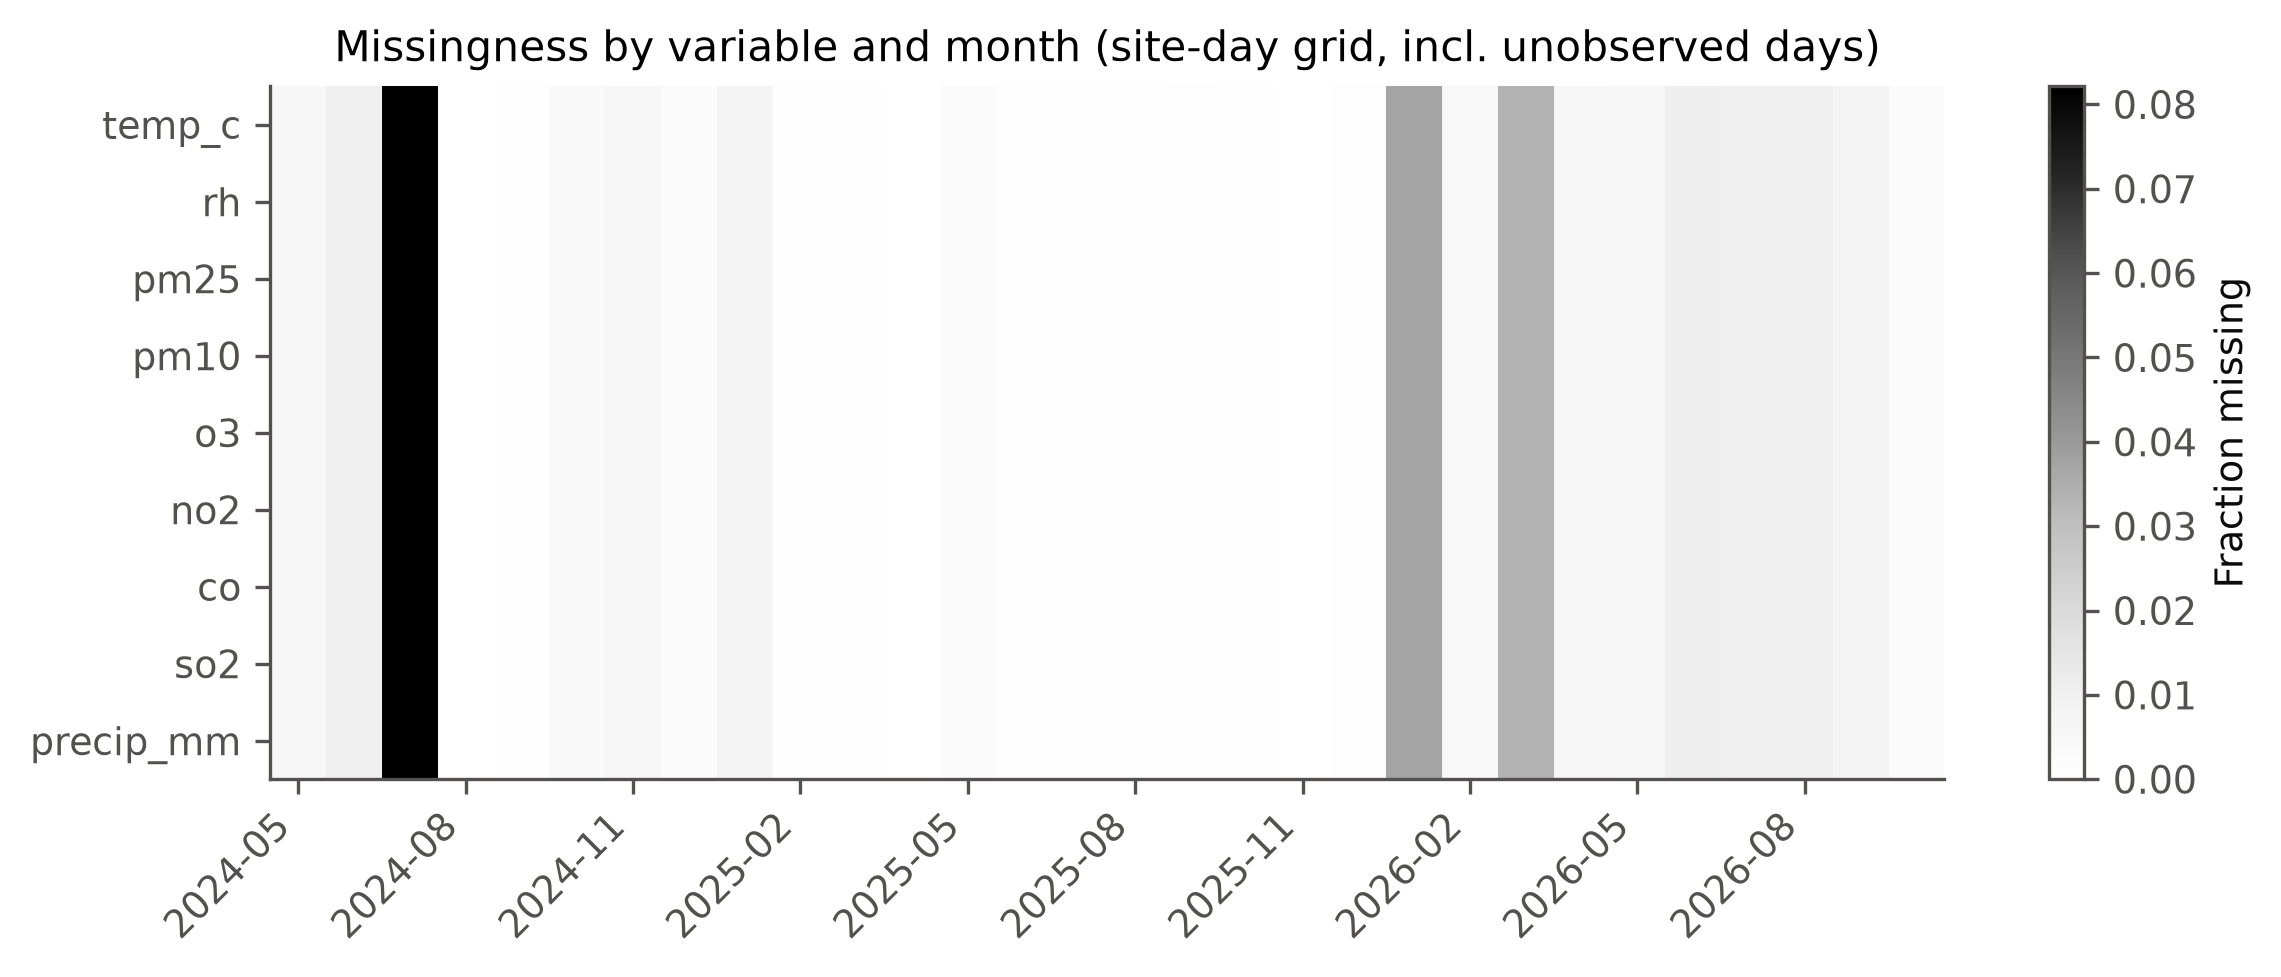

In [4]:
show("results/figures/eda/missingness_heatmap.png")

### Thermal and pollution distributions

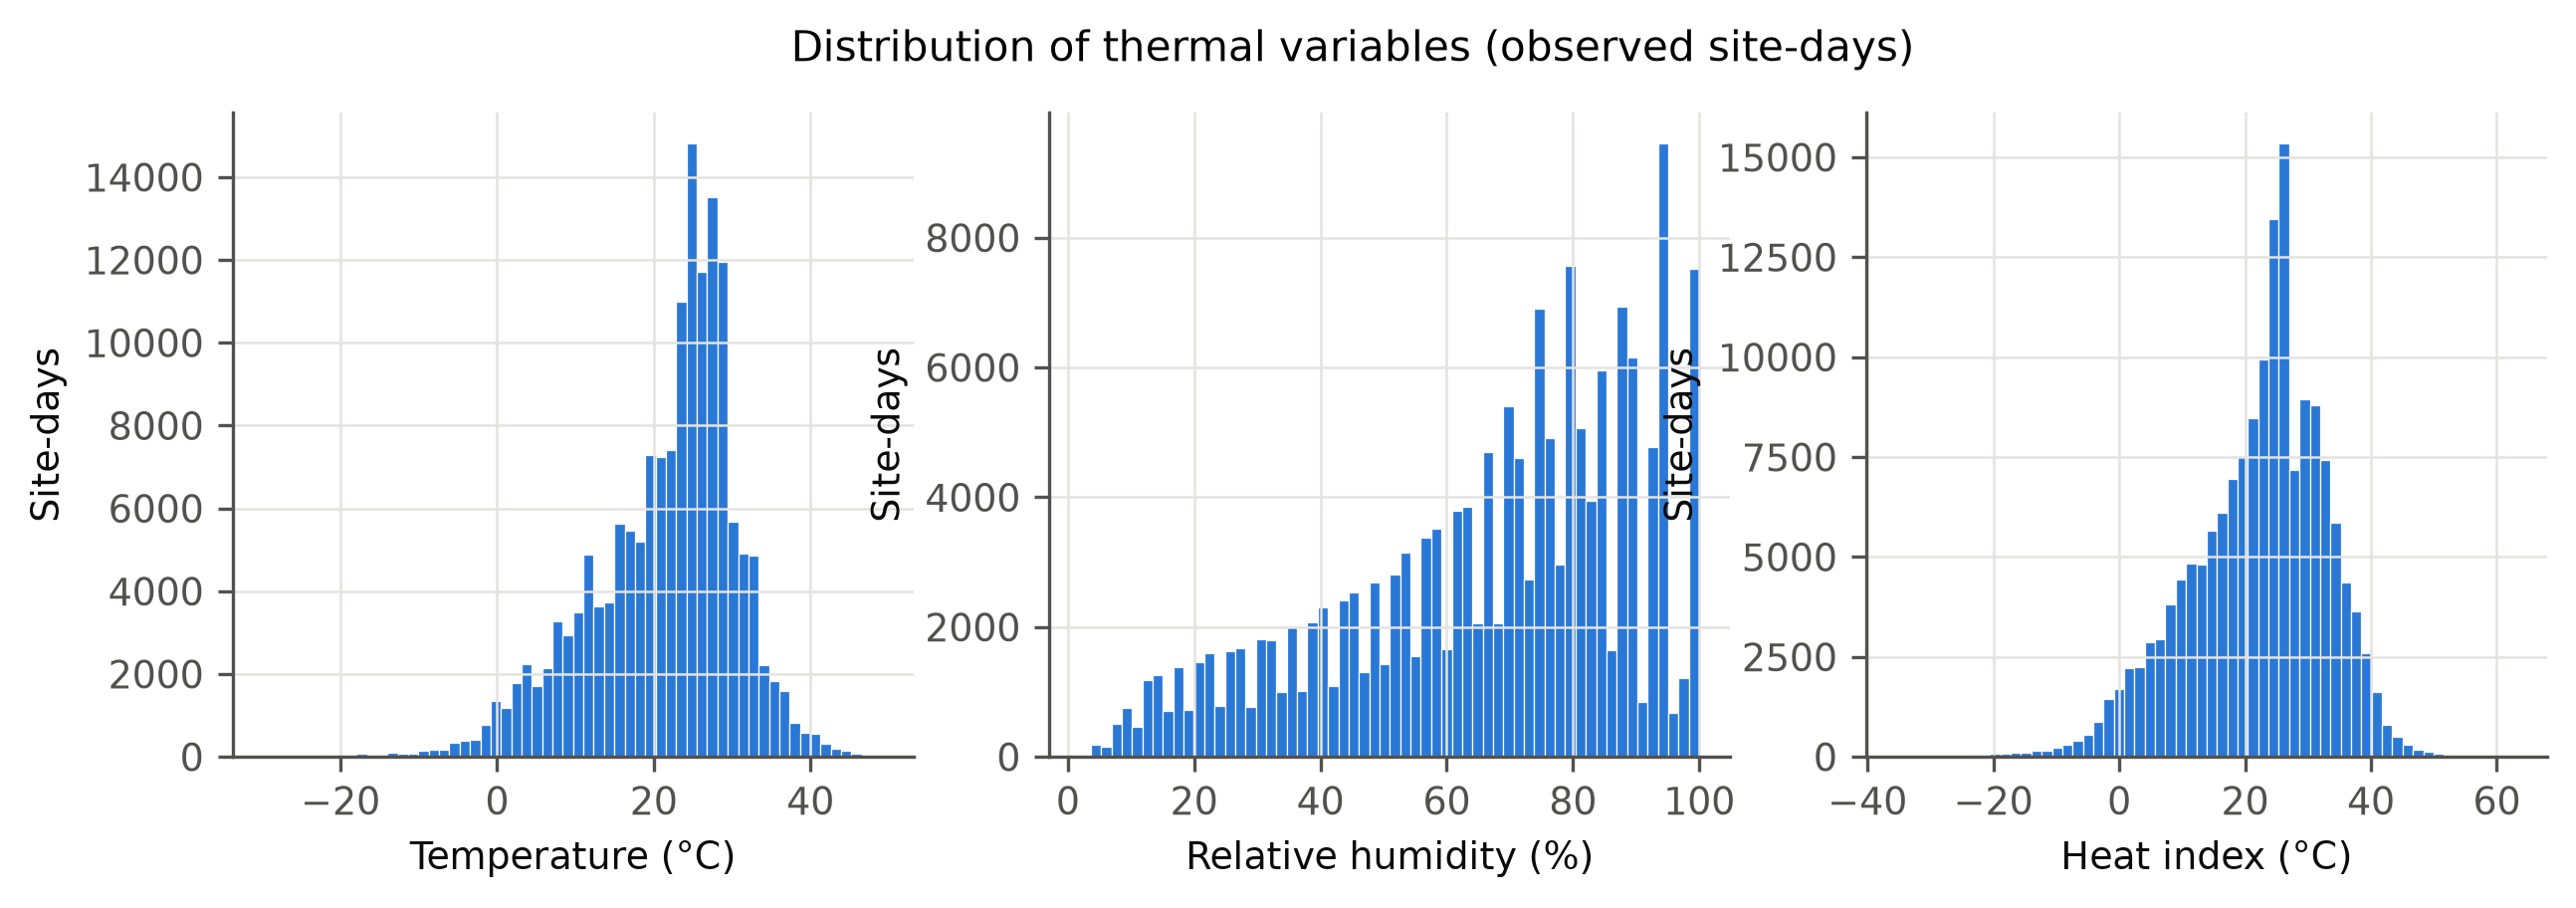

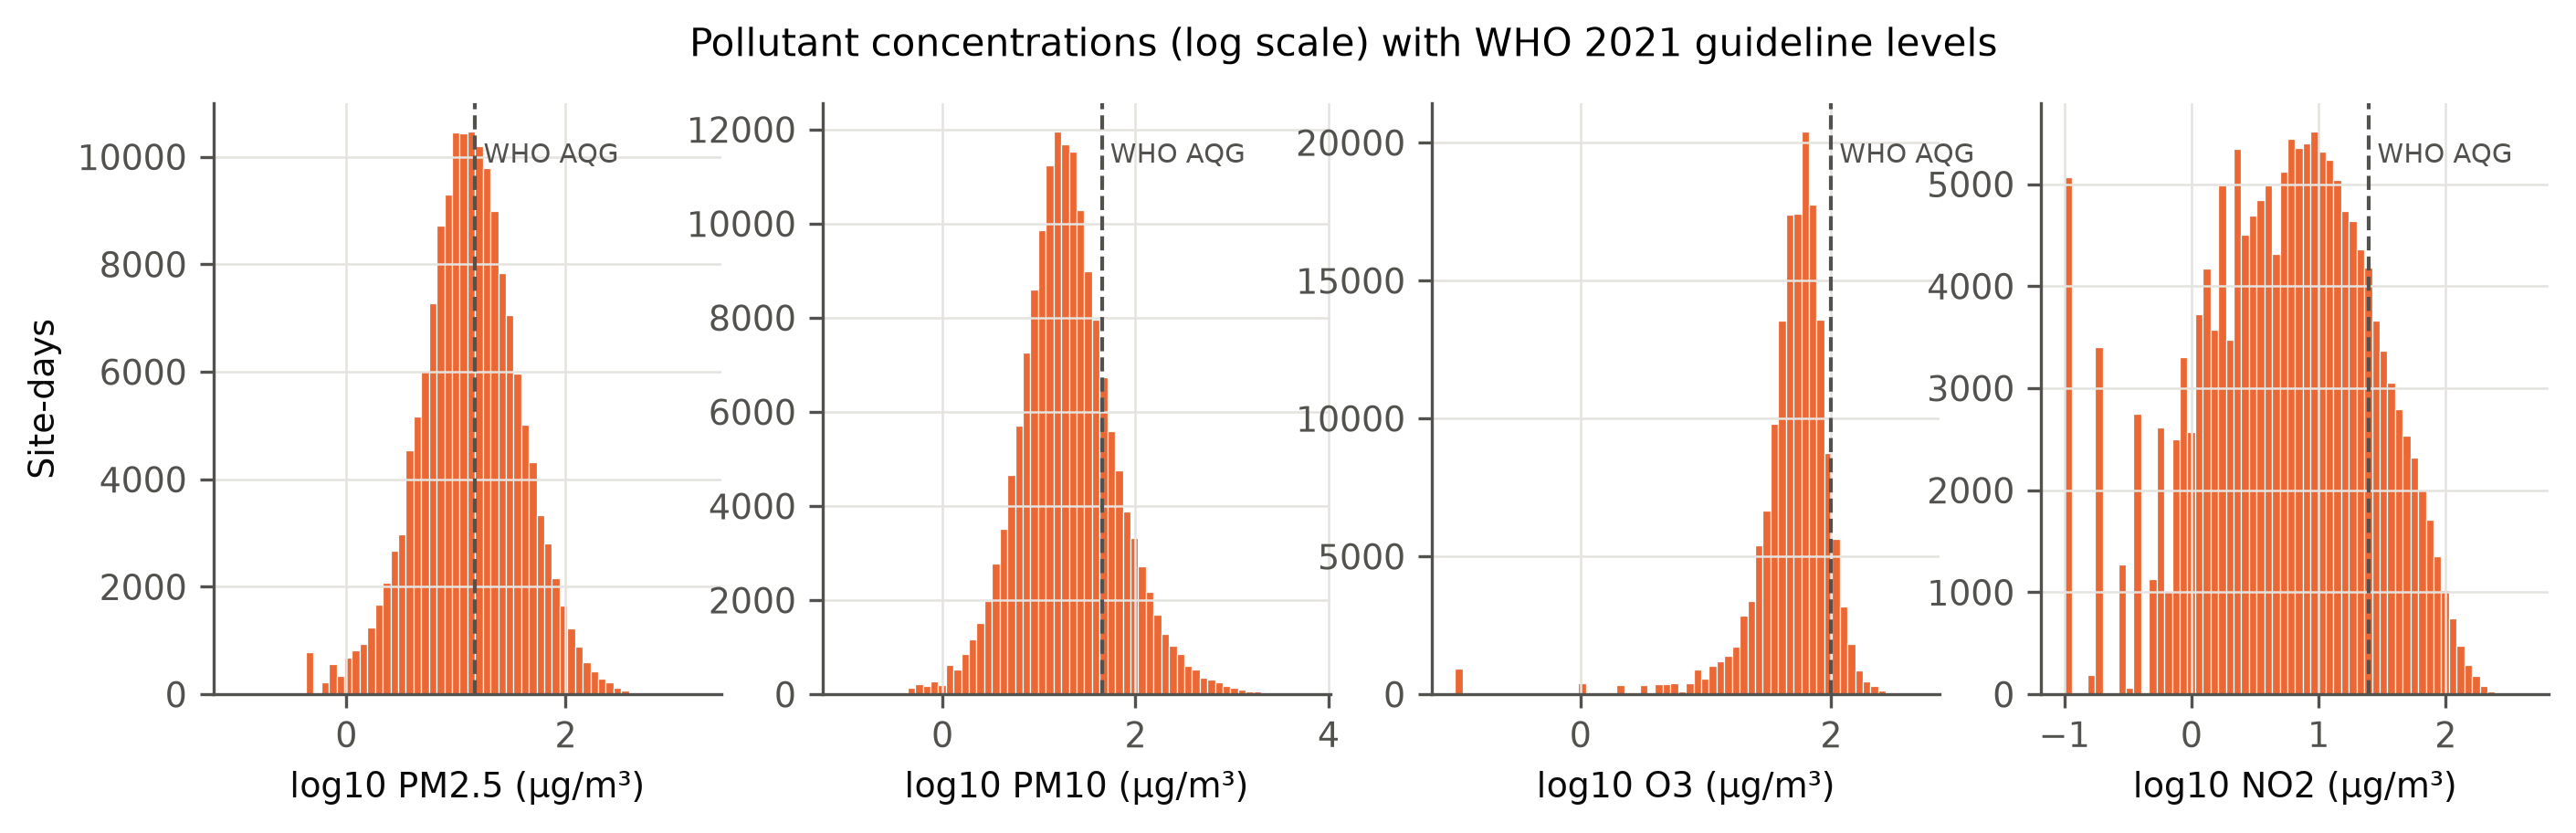

In [5]:
show("results/figures/eda/thermal_distributions.png"); show("results/figures/eda/pollution_distributions.png")

In [6]:
who = {"pm25_obs":15, "pm10_obs":45, "o3_obs":100, "no2_obs":25}
pd.Series({k: (obs[k] > v).mean()*100 for k, v in who.items()}).round(1).rename("% site-days above WHO AQG").to_frame()

,% site-days above WHO AQG
pm25_obs,45.1
pm10_obs,21.6
o3_obs,8.2
no2_obs,16.8


### Correlations
Spearman correlations are used because pollutant distributions are heavily skewed.

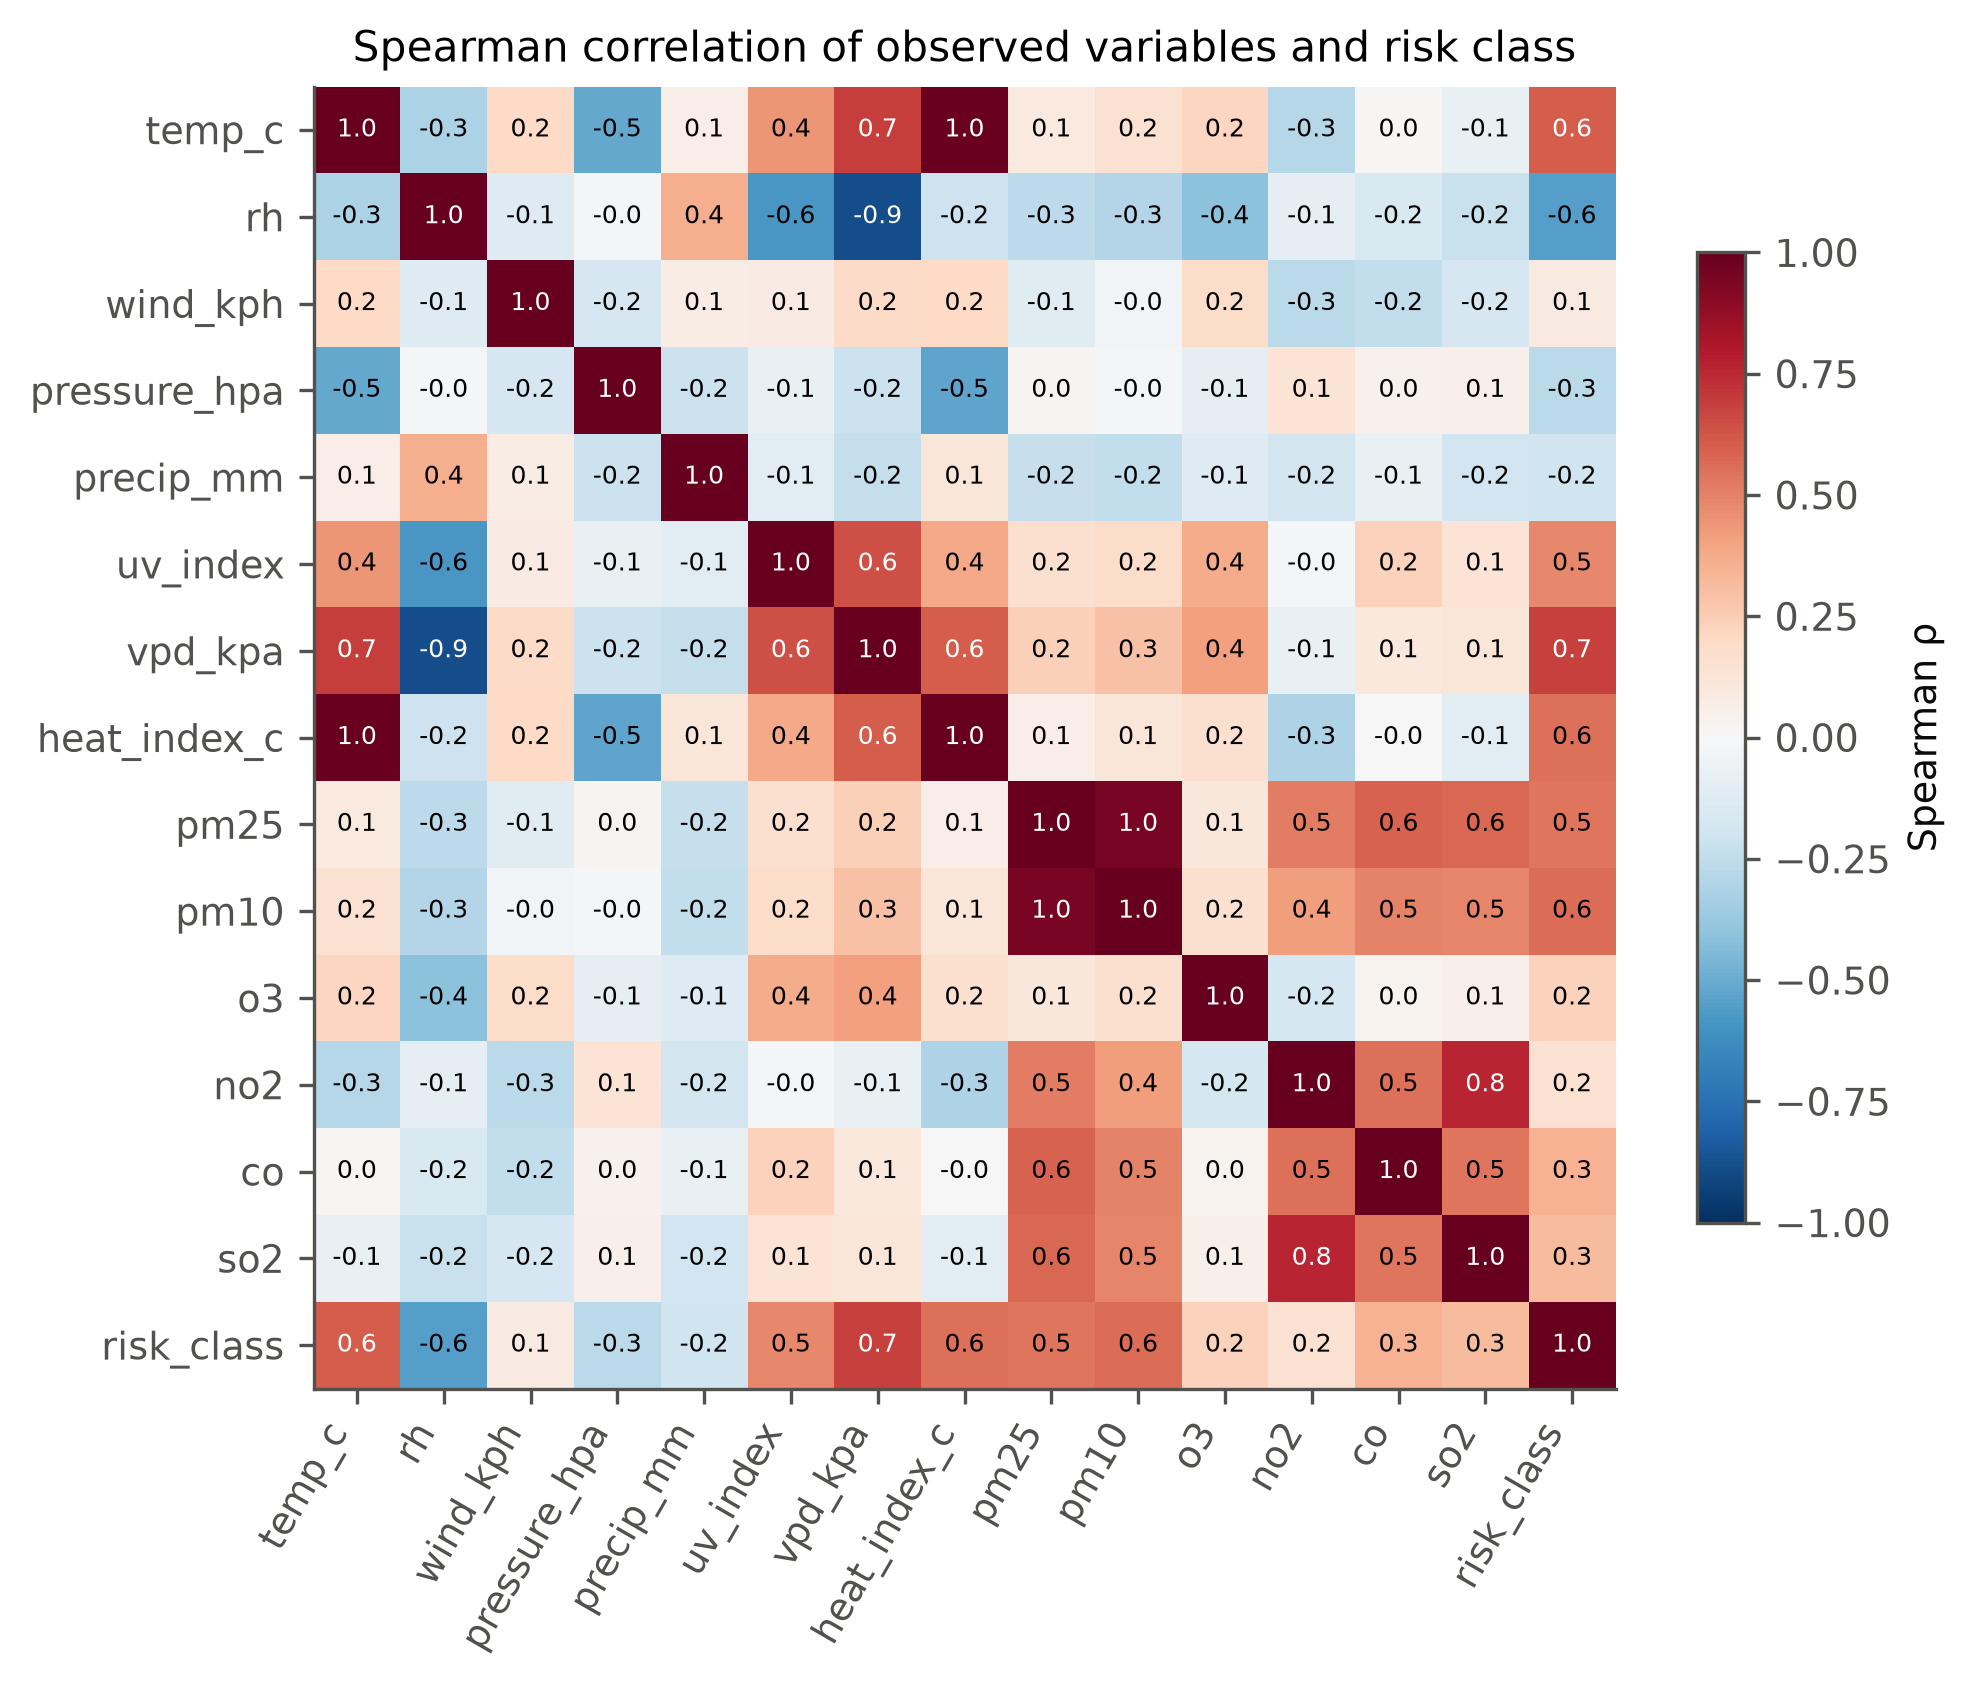

In [7]:
show("results/figures/eda/correlation_heatmap.png", 650)

### Geography and time

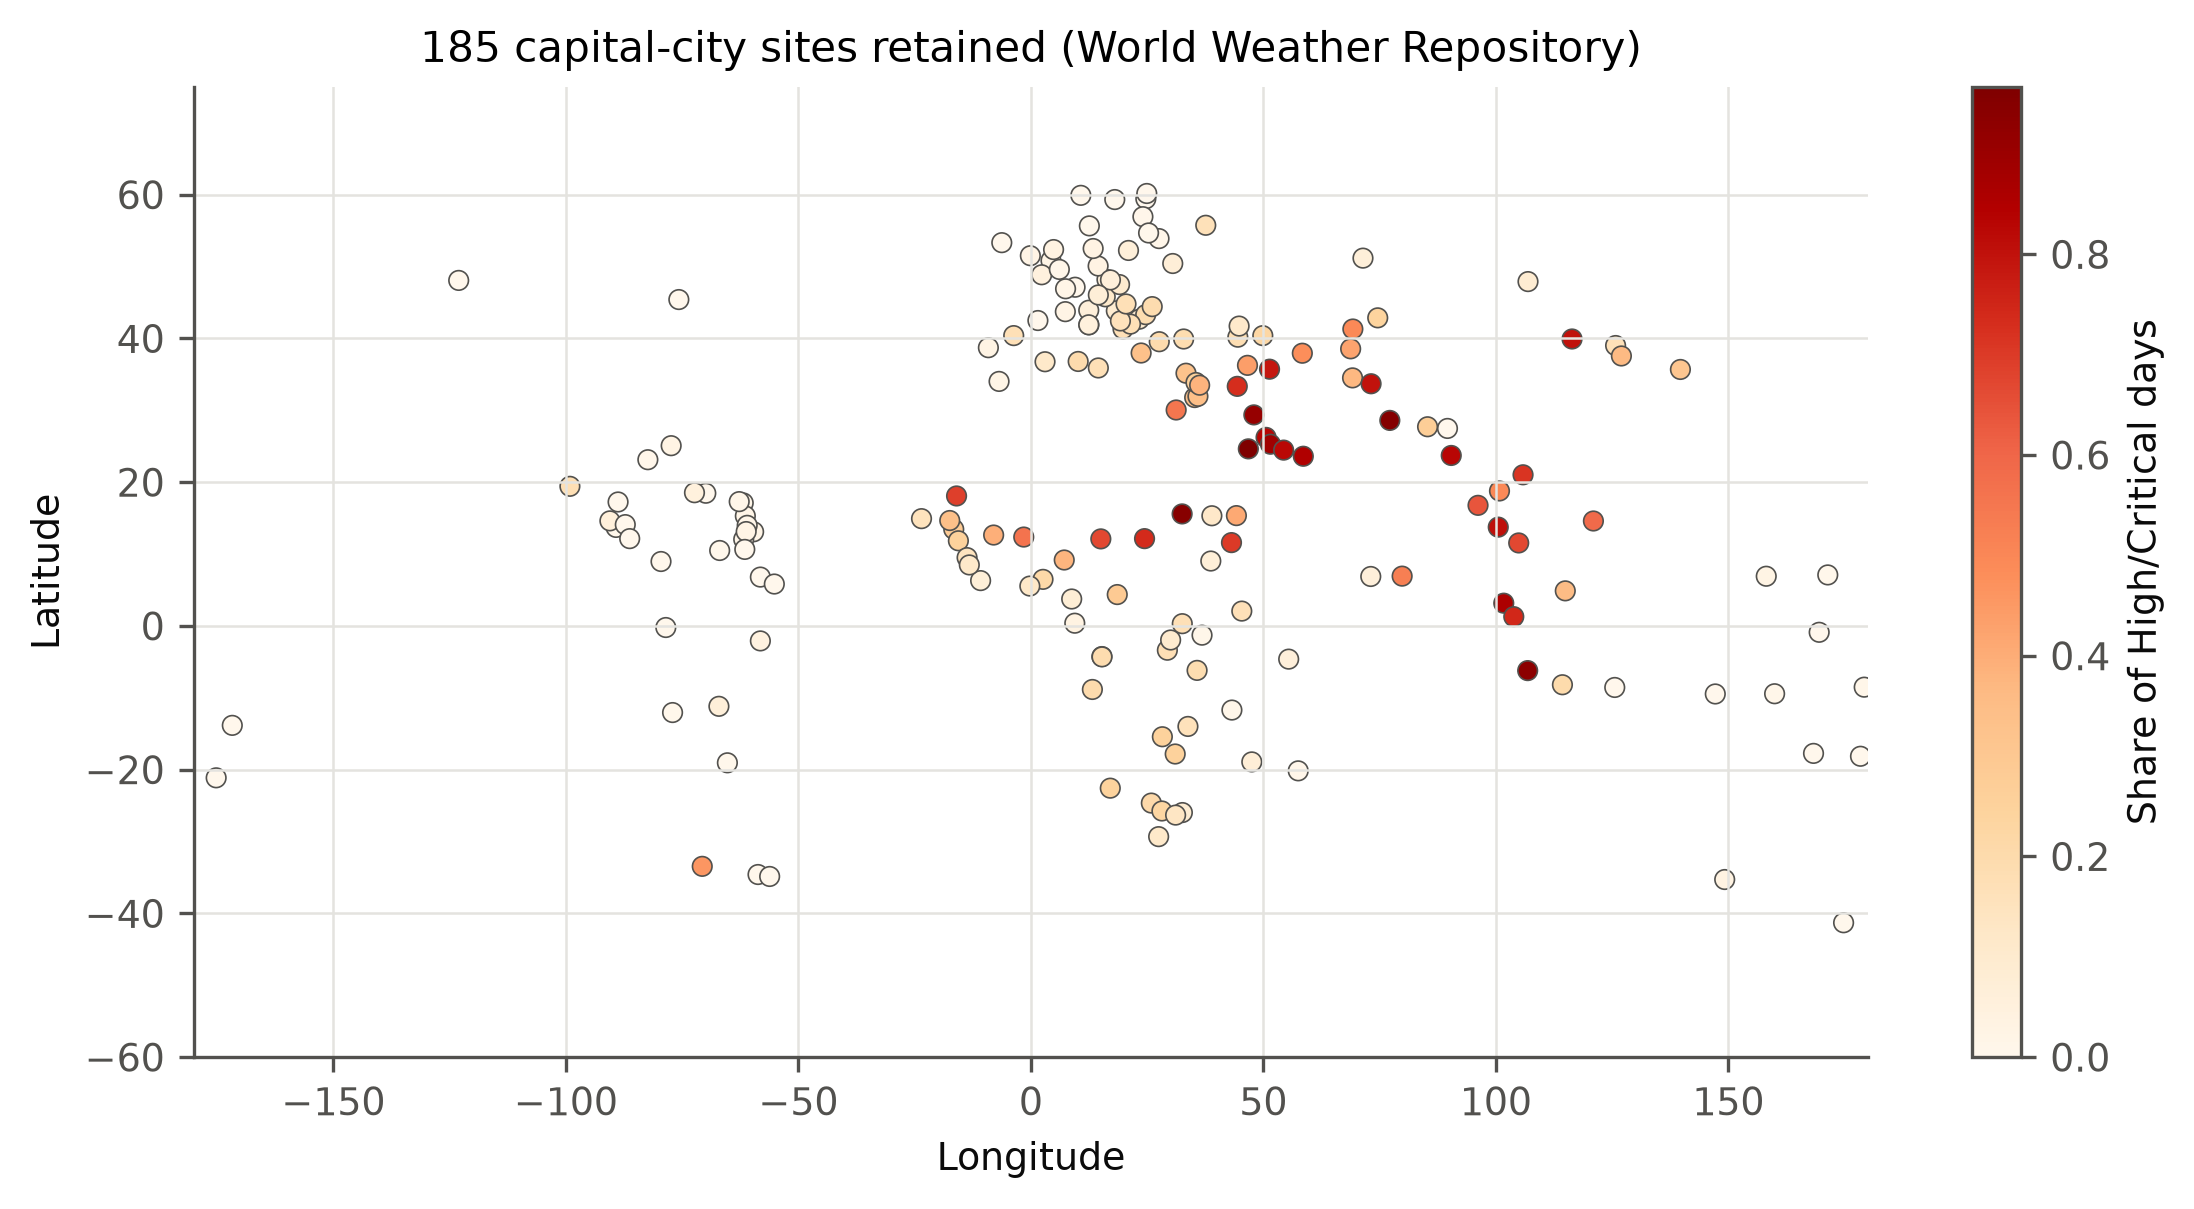

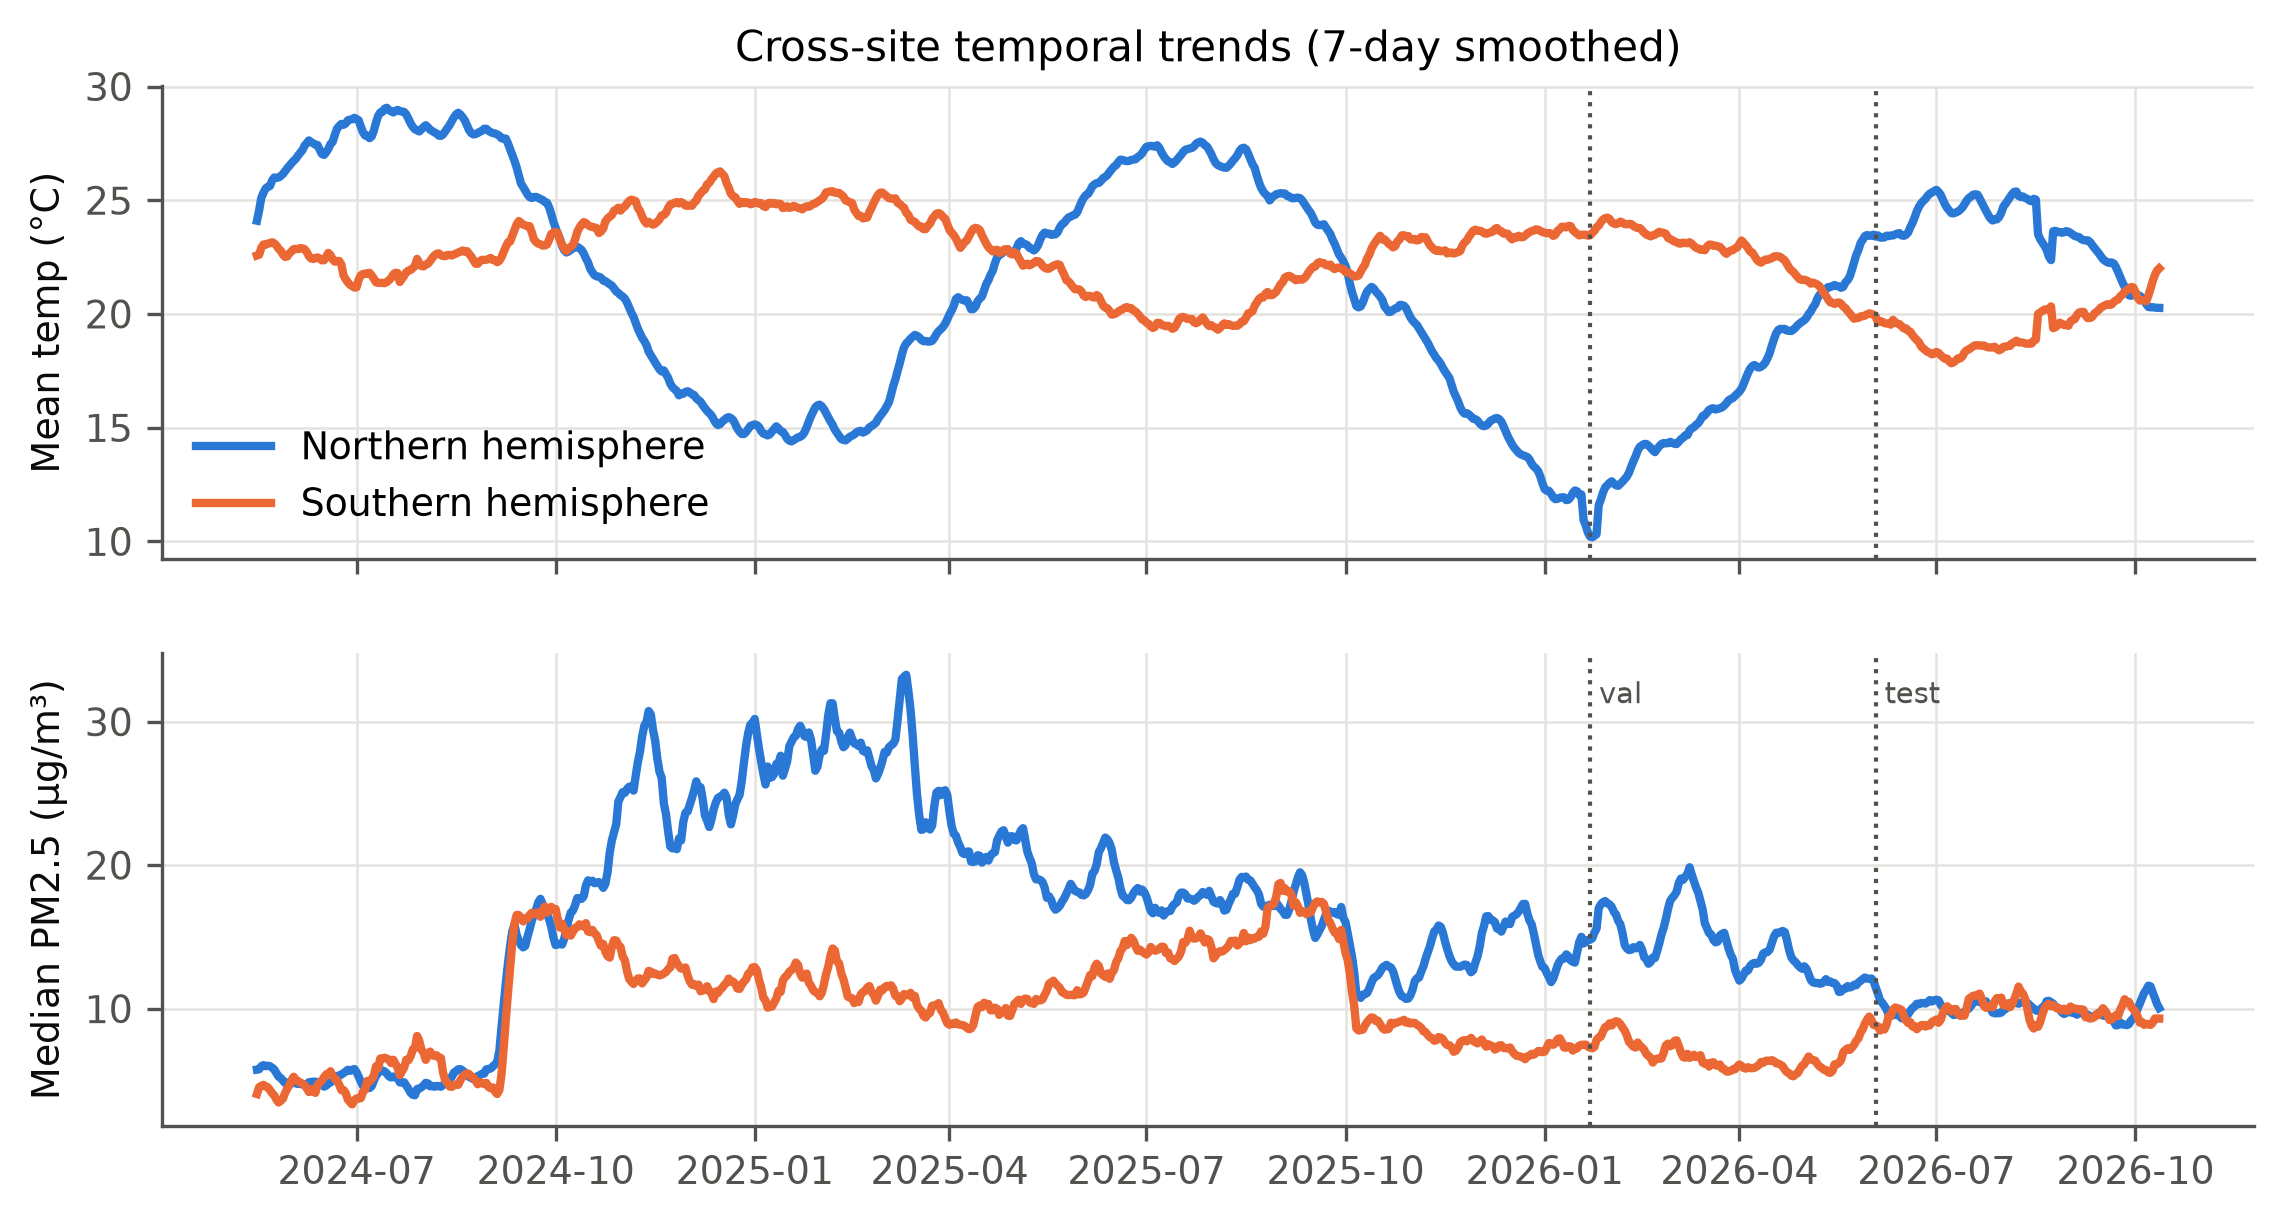

In [8]:
show("results/figures/eda/site_map_high_critical_share.png"); show("results/figures/eda/temporal_trends.png")

**Observation.** The cross-site median PM2.5 changes level abruptly around 2024-09 and
2025-10. Such step changes are typical of a change in the provider's air-quality model rather
than of the atmosphere, so they are a source of non-stationarity between training and test
periods.

### Local observation hour by longitude (sampling bias)

In [9]:
s = pd.read_csv(ROOT / "data/processed/sites.csv").set_index("site_id")
o = obs.assign(lon=obs.site_id.map(s.lon))
o.groupby(pd.cut(o.lon, [-180,-90,-30,30,90,180]), observed=True).obs_hour_obs.describe()[["mean","25%","50%","75%"]].round(1)

,mean,25%,50%,75%
lon,,,,
"(-180, -90]",11.1,2.2,6.5,21.2
"(-90, -30]",4.6,2.5,4.2,5.8
"(-30, 30]",10.0,8.0,9.8,11.5
"(30, 90]",12.2,10.2,12.0,13.8
"(90, 180]",16.9,15.0,17.2,19.2


The snapshot is taken at nearly the same UTC instant everywhere, so the local hour runs from
≈04 h in the Americas to ≈17 h in East Asia. Heat-related variables are therefore sampled at
different phases of the diurnal cycle — a key limitation carried through to the labels.

### Seasonality, dryness proxy and Berkeley Earth context

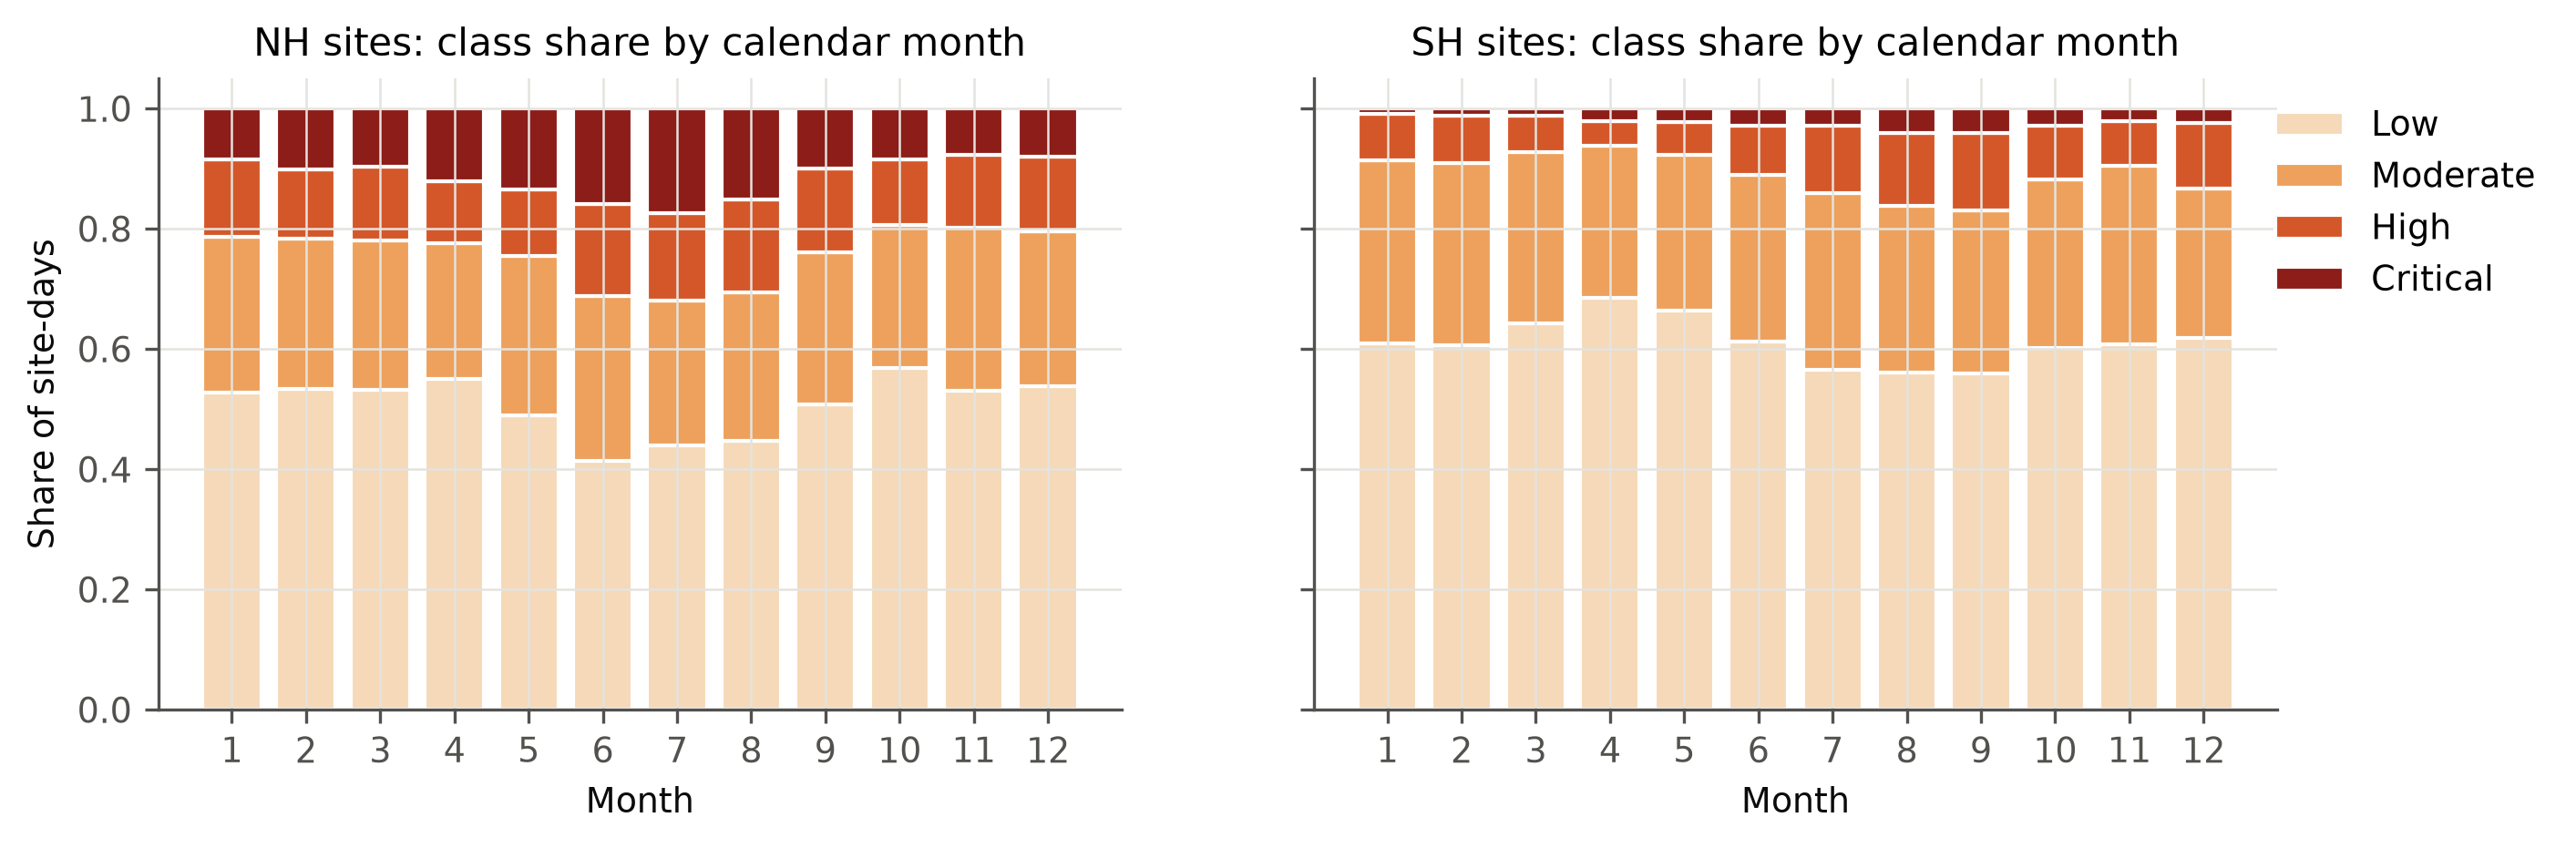

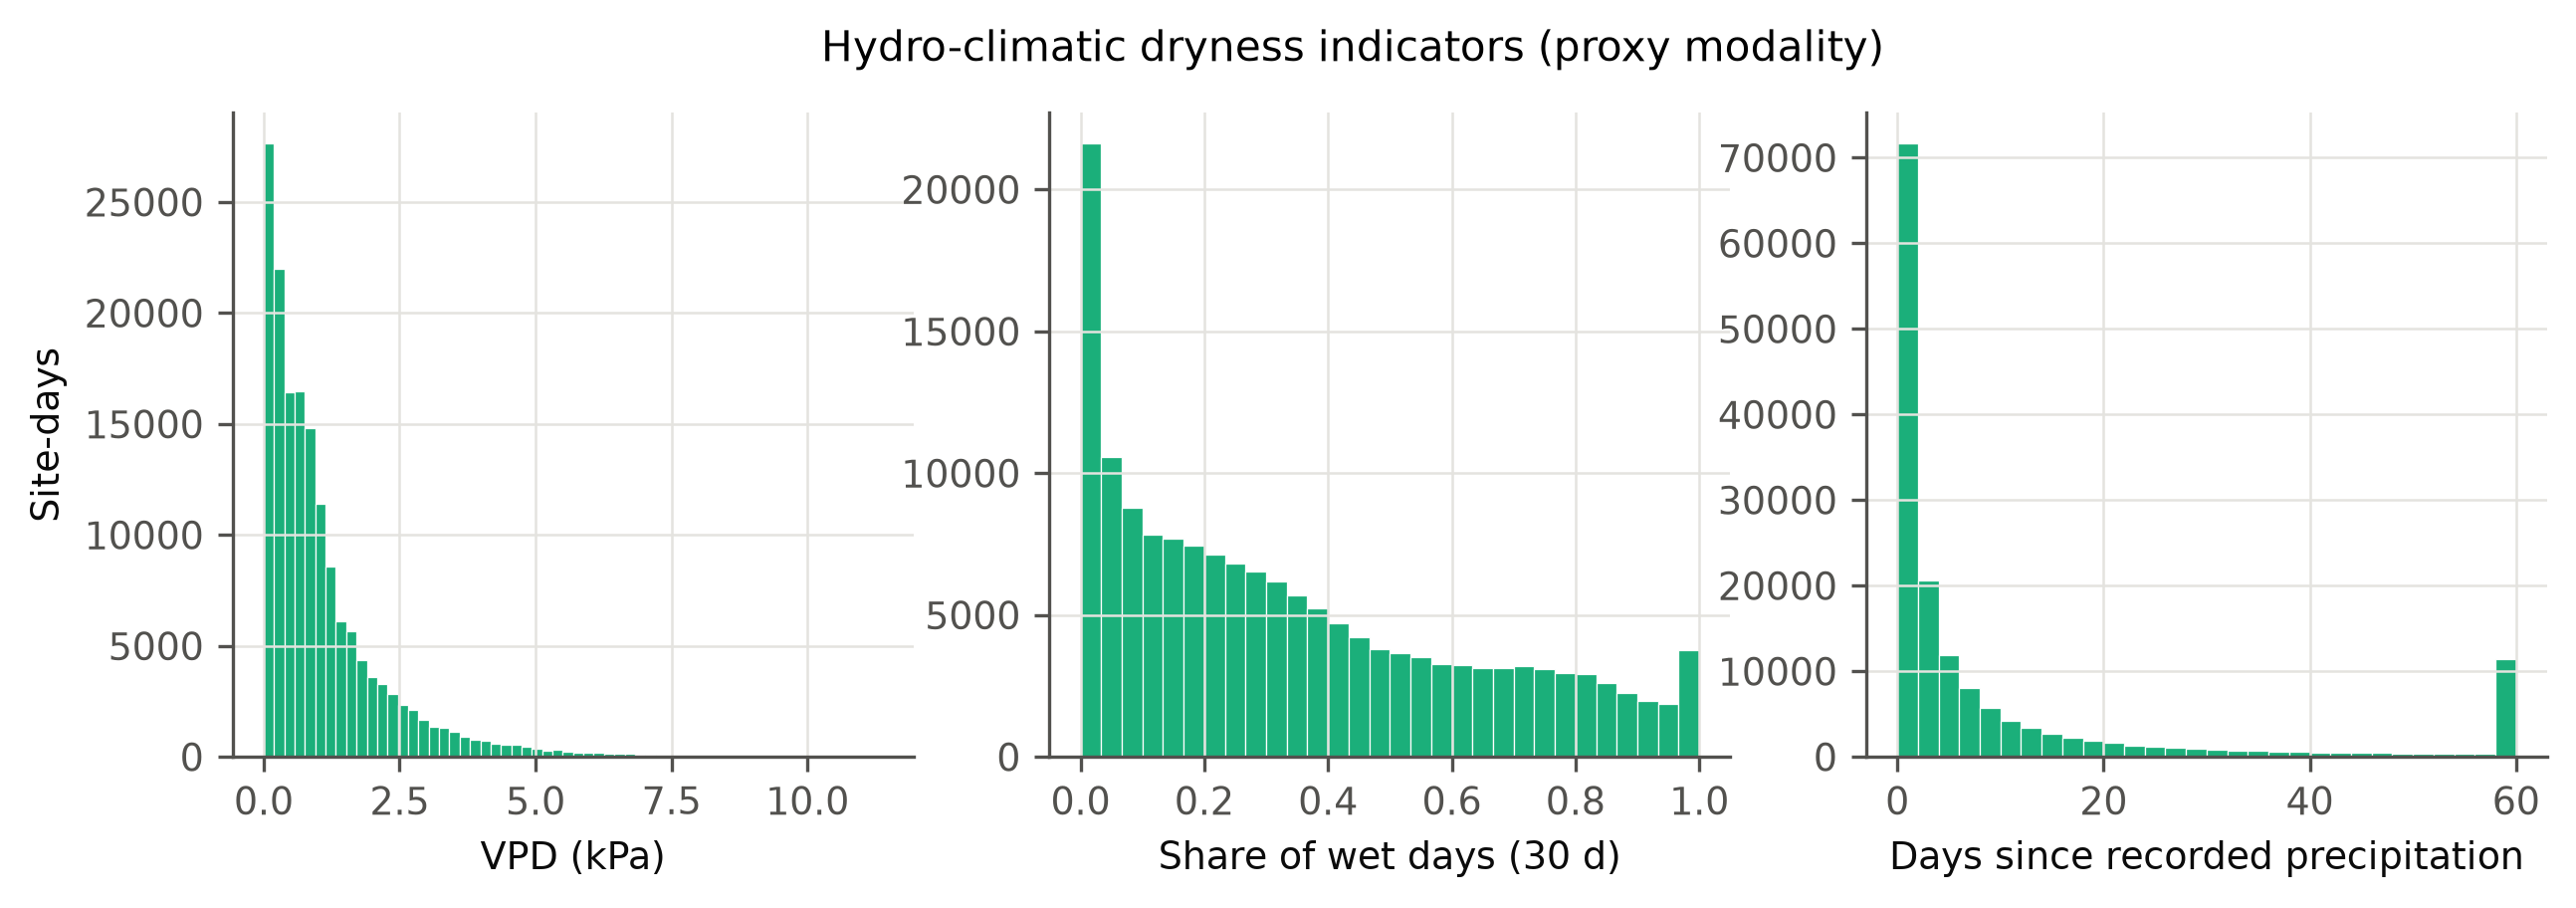

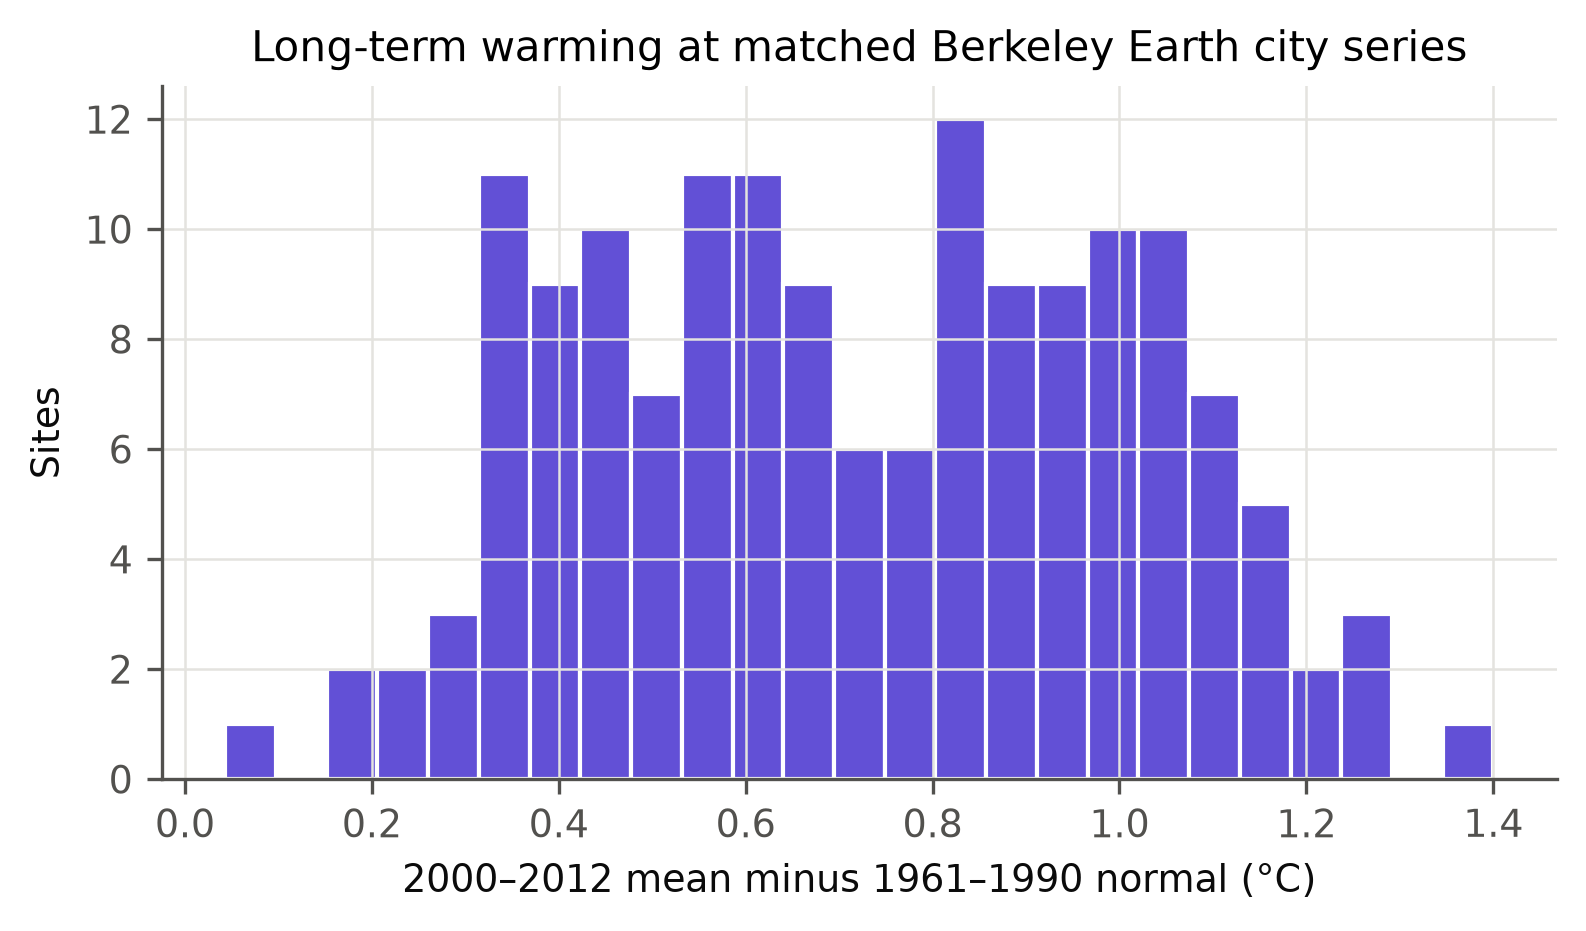

In [10]:
show("results/figures/eda/seasonal_class_distribution.png"); show("results/figures/eda/dryness_indicators.png"); show("results/figures/eda/berkeley_warming.png", 550)

### Auxiliary US drought data

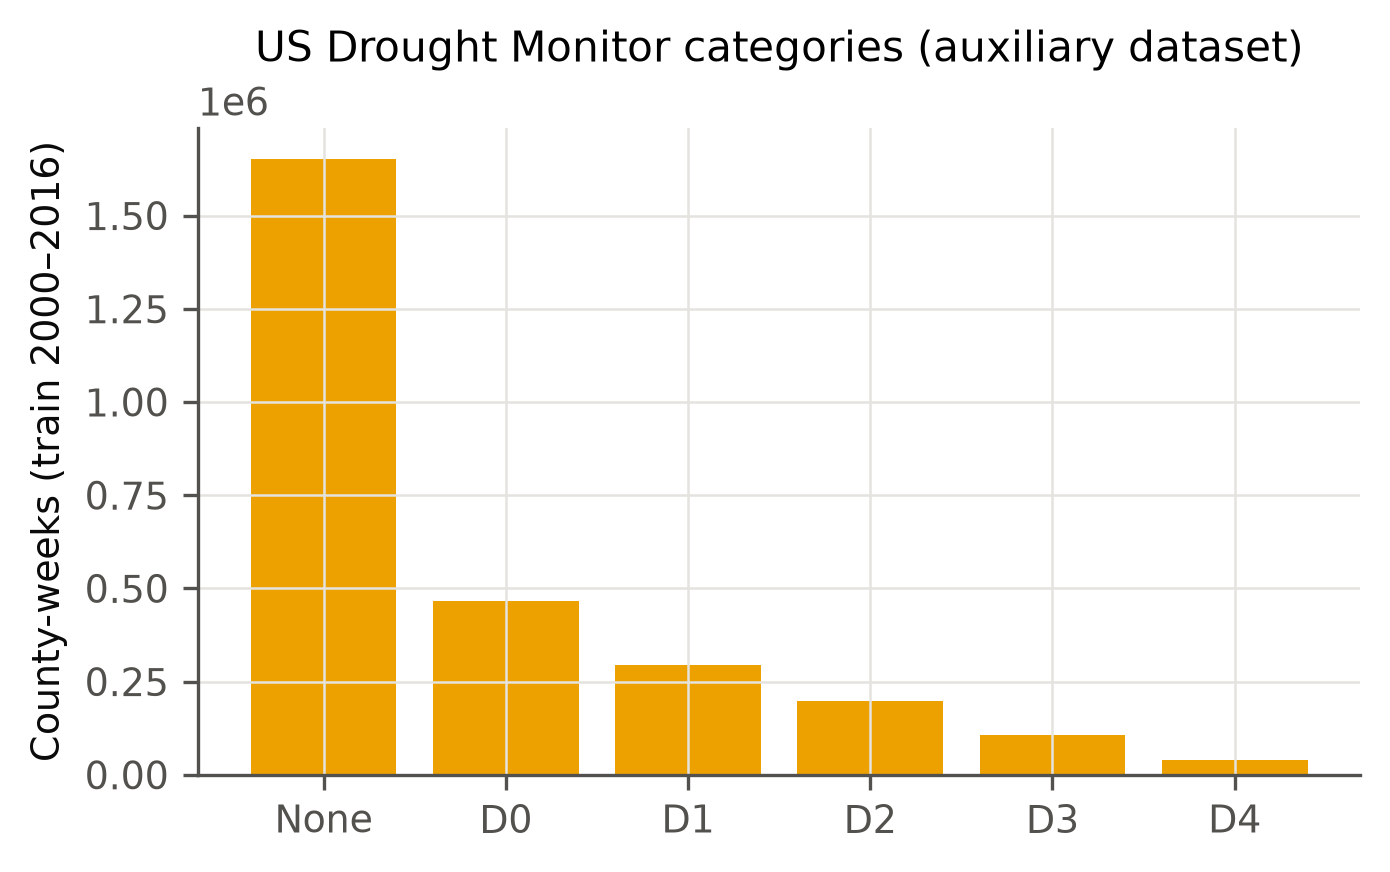

In [11]:
show("results/figures/eda/us_drought_score_distribution.png", 500)